In [11]:
# preparing python environment for analysis
import pandas as pd
import sqlalchemy
import psycopg
import matplotlib.pyplot as plt

print("pandas",pd.__version__)
print("SQLalchemy", sqlalchemy.__version__)
print("postgresSQL driver",psycopg.__version__)
print("python envernonment is ready!")


pandas 3.1.0
SQLalchemy 2.1.6
postgresSQL driver 3.3.6
python envernonment is ready!


In [9]:
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from getpass import getpass

db_user = "postgres"
db_password = getpass("Enter PostgreSQL password: ")
db_host = "localhost"
db_port = 5433
db_name = "postgres"

connection_url = URL.create(
    drivername="postgresql+psycopg",
    username=db_user,
    password=db_password,
    host=db_host,
    port=db_port,
    database=db_name
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    result = connection.execute(text("SELECT current_database();"))
    print("Connected to database:", result.scalar())

print("PostgreSQL connection successful!")

Connected to database: postgres
PostgreSQL connection successful!


In [10]:
# SECTION 3: Validate E-commerce Database Tables
# Business purpose:
# Verify that Python can access the three core tables.
# Compare record counts with our previous PostgreSQL analysis.

query = """
SELECT 'website_sessions' AS table_name,
       COUNT(*) AS total_records
FROM website_sessions

UNION ALL

SELECT 'website_pageviews' AS table_name,
       COUNT(*) AS total_records
FROM website_pageviews

UNION ALL

SELECT 'orders' AS table_name,
       COUNT(*) AS total_records
FROM orders;
"""

# Execute SQL query and load results into a Pandas DataFrame
df_table_counts = pd.read_sql(query, engine)

# Display results
display(df_table_counts)


,table_name,total_records
0,orders,32313
1,website_sessions,472871
2,website_pageviews,1188124


In [15]:
# identifying the available columns and their data types
tables =[
    "website_sessions",
    "website_pageviews",
    "orders"
]
for table in tables:
    print(f"\n--- {table.upper()} ---")
    query = f"""
    select *
    from {table}
    limit 5
    """
    df = pd.read_sql(query,engine)
    display(df)
    print(f"\ncolumn data types:")
    print(df.dtypes)


--- WEBSITE_SESSIONS ---


,website_session_id,created_at,user_id,is_repeat-session,utm_source,utm_campaign,utm_content,device_type,http_referer
0,1,2012-03-19 08:04:16,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
1,2,2012-03-19 08:16:49,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
2,3,2012-03-19 08:26:55,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
3,4,2012-03-19 08:37:33,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
4,5,2012-03-19 09:00:55,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com



column data types:
website_session_id             int64
created_at            datetime64[us]
user_id                        int64
is_repeat-session              int64
utm_source                       str
utm_campaign                     str
utm_content                      str
device_type                      str
http_referer                     str
dtype: object

--- WEBSITE_PAGEVIEWS ---


,website_pageview_id,created_at,website_session_id,pageview_url
0,1,2012-03-19 08:04:16,1,/home
1,2,2012-03-19 08:16:49,2,/home
2,3,2012-03-19 08:26:55,3,/home
3,4,2012-03-19 08:37:33,4,/home
4,5,2012-03-19 09:00:55,5,/home



column data types:
website_pageview_id             int64
created_at             datetime64[us]
website_session_id              int64
pageview_url                      str
dtype: object

--- ORDERS ---


,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,160,160,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,177,177,1,1,49.99,19.49



column data types:
order_id                       int64
created_at            datetime64[us]
website_session_id             int64
user_id                        int64
primary_product_id             int64
items_purchased                int64
price_usd                    float64
cogs_usd                     float64
dtype: object


In [17]:
# mobile vs desktop funnel analysis
# at which stage of purchasce funnel do mobile and desktop vistors drop off?
query = """
with session_steps as (
    select 
       s.website_session_id,
       s.device_type,
       max(case when p.pageview_url ='/products'
                then 1 else 0 end) as reached_products,
        max(case when p.pageview_url = '/cart'
                then 1 else 0 end) as reached_cart,
        max(case when p.pageview_url = '/shipping'
                then 1 else 0 end) as reached_shipping,
        max(case when p.pageview_url = '/billing'
                then 1 else 0 end) as reached_billing,
        max(case when p.pageview_url ='/thank_you_for_your_order'
                then 1 else 0 end) as reached_purchase
    from website_sessions s
    left join website_pageviews p
        on s.website_session_id = p.website_session_id
    group by 
       s.website_session_id,
       s.device_type
)
select
   device_type,
   count(*) filter(where reached_products = 1) as products,
   count(*) filter(where reached_cart = 1) as cart,
   count(*) filter(where reached_shipping = 1) as shipping,
   count(*) filter(where reached_billing = 1) as billing,
   count(*) filter(where reached_purchase = 1) as purchase
from session_steps
group by device_type;
"""
df_funnel = pd.read_sql(query,engine)
display(df_funnel)

,device_type,products,cart,shipping,billing,purchase
0,mobile,68906,19798,11792,411,0
1,desktop,192325,75155,52692,3206,0


In [18]:
# preparing website sessions,pageviews andorders
df_sessions = pd.read_sql(
    """
    select website_session_id,device_type,created_at
    from website_sessions
    """,
    engine
) 
df_pageviews = pd.read_sql(
    """
    select website_pageview_id,website_session_id,pageview_url,created_at
    from website_pageviews
    """,
    engine
)
df_orders = pd.read_sql(
    """
    select order_id,website_session_id
    from orders
    """,
    engine
)
print("sessions:",df_sessions.shape)
print("pageviews:",df_pageviews.shape)
print("orders:",df_orders.shape)

sessions: (472871, 3)
pageviews: (1188124, 4)
orders: (32313, 2)


In [26]:
# data quality validation
# checking missing values
print("missing values-sessions:")
print(df_sessions.isna().sum())
print("\nmissing values-pageviews:")
print(df_pageviews.isna().sum())
print("\nmissing values-orders:")
print(df_orders.isna().sum())
# checking duplicate primary IDS
print("\nDuplicate IDs")
print("sessions:",
df_sessions["website_session_id"].duplicated().sum())
print("pageviews:",
df_pageviews["website_pageview_id"].duplicated().sum())
print("orders:",
df_orders["order_id"].duplicated().sum())
# checking weather order date exist in session data
invalid_order_sessions = (
    ~df_orders["website_session_id"].isin(
        df_sessions["website_session_id"]
    )
).sum()
print("\norders with unknown session IDs:",invalid_order_sessions)
# identify the actual billing and purchase page url
print("\nBilling and order-related page URLs:")
page_counts = df_pageviews["pageview_url"].value_counts()
relevant_pages = page_counts[
    page_counts.index.str.contains(
        "bill|thank|order",
        case = False,
        na = False
    )
]
print(relevant_pages)

missing values-sessions:
website_session_id    0
device_type           0
created_at            0
dtype: int64

missing values-pageviews:
website_pageview_id    0
website_session_id     0
pageview_url           0
created_at             0
dtype: int64

missing values-orders:
order_id              0
website_session_id    0
dtype: int64

Duplicate IDs
sessions: 0
pageviews: 0
orders: 0

orders with unknown session IDs: 0

Billing and order-related page URLs:
pageview_url
/billing-2                   48441
/thank-you-for-your-order    32313
/billing                      3617
Name: count, dtype: int64


In [42]:
# how meny mobile and desktop sessionsreached each funnelstage?
stage_urls ={
"/products": "products",
"/cart":"cart",
"/shipping":"shipping",
"/billing":"billing",
"/billing-2":"billing"
}
# keeping only relevent pageviews
df_stages = df_pageviews[
    df_pageviews["pageview_url"].isin(stage_urls)
].copy()
# assagining funnelstage each pageviews
df_stages["stages"] = df_stages["pageview_url"].map(stage_urls)
session_stages = (
    pd.crosstab(
        df_stages["website_session_id"],
        df_stages["stages"]
    )
    .gt(0)
    .astype(int)
    .reset_index()
)
# connecting funnel stages to sessions
df_funnel_sessions = df_sessions.merge(
    session_stages,
    on = "website_session_id",
    how = "left"
)
stages = ["products","cart","shipping","billing"]
df_funnel_sessions[stages]=(
    df_funnel_sessions[stages].fillna(0).astype(int)
)
# identify sessions that generated orders
df_funnel_sessions["purchase"] = (
    df_funnel_sessions["website_session_id"]
    .isin(df_orders["website_session_id"])
    .astype(int)
)
# calculate funnel count by device 
df_funnel_summary = (
    df_funnel_sessions
    .groupby("device_type")[
        stages+["purchase"]
    ]
    .sum()
    .reset_index()
)
print("billing pageviews included:")
print(
    df_stages.loc[
        df_stages["stages"] == "billing",
        "pageview_url"
    ].value_counts()
)
print("\nupdated device funnel:")
display(df_funnel_summary)

billing pageviews included:
pageview_url
/billing-2    48441
/billing       3617
Name: count, dtype: int64

updated device funnel:


,device_type,products,cart,shipping,billing,purchase
0,desktop,192325,75155,52692,43722,27805
1,mobile,68906,19798,11792,8336,4508


In [45]:
# funnel conversion and drop-off analysis
stages = ["products","cart","shipping","billing","purchase"]
# copying the funnel summary
df_conversion = df_funnel_summary.copy()
# calculating stage-to-stage progression percentage
for i in range(len(stages)-1):
    current_stage = stages[i]
    next_stage = stages[i+1]
    rate_column = f"{current_stage}_to_{next_stage}_pct"
    df_conversion[rate_column] =(
        df_conversion[next_stage]/df_conversion[current_stage]*100
    ).round(2)
    # pick the percentage columns
    rate_columns =[
        col for col in df_conversion.columns
        if col.endswith("_pct")
    ]
    display(df_conversion[["device_type"]+rate_columns])


,device_type,products_to_cart_pct
0,desktop,39.08
1,mobile,28.73


,device_type,products_to_cart_pct,cart_to_shipping_pct
0,desktop,39.08,70.11
1,mobile,28.73,59.56


,device_type,products_to_cart_pct,cart_to_shipping_pct,shipping_to_billing_pct
0,desktop,39.08,70.11,82.98
1,mobile,28.73,59.56,70.69


,device_type,products_to_cart_pct,cart_to_shipping_pct,shipping_to_billing_pct,billing_to_purchase_pct
0,desktop,39.08,70.11,82.98,63.59
1,mobile,28.73,59.56,70.69,54.08


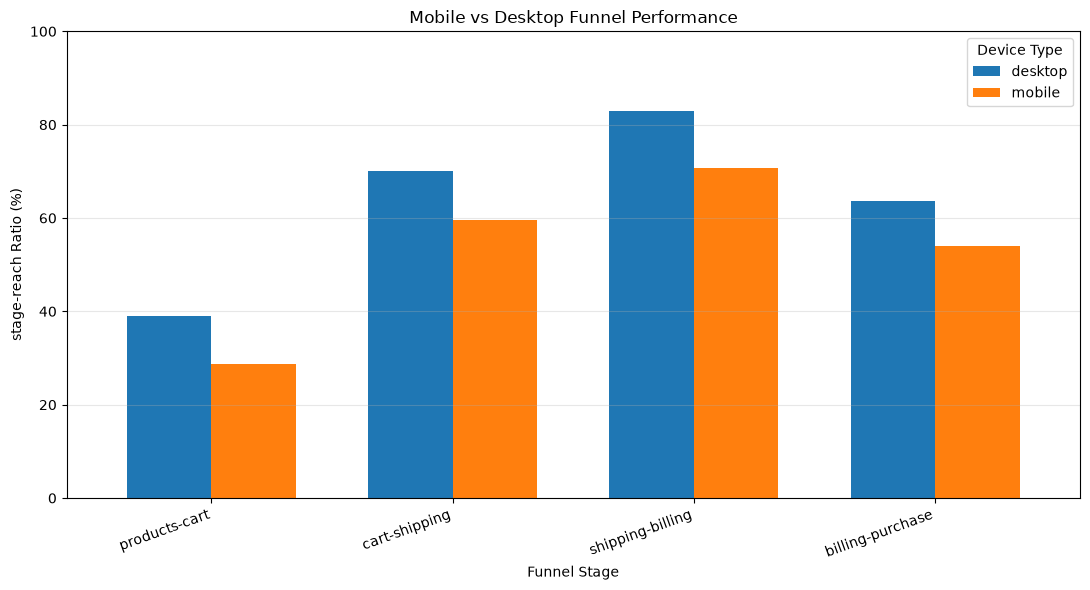

In [46]:
# visualize mobile vs desktop funnel performance
# identify the stages with the largest conversion gaps.
# organize conversion rates for comparision
df_chart = df_conversion.set_index("device_type")[rate_columns].T
df_chart.index = [
    "products-cart",
    "cart-shipping",
    "shipping-billing",
    "billing-purchase"
]
# create a grouped bar chart
ax = df_chart[["desktop","mobile"]].plot(
    kind = "bar",
    figsize = (11,6),
    width = 0.7
)
# formating the visualization
plt.title("Mobile vs Desktop Funnel Performance")
plt.xlabel("Funnel Stage")
plt.ylabel("stage-reach Ratio (%)")
plt.xticks(rotation = 20,ha = "right")
plt.ylim(0,100)
plt.legend(title = "Device Type")
plt.grid(axis = "y",alpha = 0.3)
# display the chart
plt.tight_layout()
plt.show()

In [52]:
# final validation and export
from pathlib import Path
# validate pageview relationships
invalid_pageviews = (
    ~df_pageviews["website_session_id"].isin(
        df_sessions["website_session_id"]
    )
).sum()
print("pageviews with unknown session IDs:",invalid_pageviews)
# validate purchase counts
actual_purchasing_sessions = df_orders["website_session_id"].nunique()
funnel_purchasing_sessions = df_funnel_summary["purchase"].sum()
# comparing desktop and mobile progression percentages
df_rates = df_conversion.set_index("device_type")[rate_columns]
df_gap = pd.DataFrame({
    "funnel_stage": [
        "products to cart",
        "cart to shipping",
        "shipping to Billing",
        "Billing to purchase"
    ],
    "desktop_pct":df_rates.loc["desktop"].to_numpy(),
    "mobile_pct":df_rates.loc["mobile"].to_numpy()
})
df_gap["gap_percentage_points"]=(
    df_gap["desktop_pct"] - df_gap["mobile_pct"]
).round(2)
display(df_gap)
# create output folder
Path("outputs").mkdir(exist_ok = True)
# export datasets
df_funnel_summary.to_csv(
    "outputs/device_funnel_counts.csv",
    index = False
)
df_gap.to_csv(
    "outputs/device_funnel_comparision.csv",
    index = False
)
# export the matplotlib chart
ax.figure.savefig(
    "outputs/device_funnel_comparison.png",
    dpi = 200,
    bbox_inches = "tight"
)
print("\nAnalysis outputs saved successfully!")

pageviews with unknown session IDs: 0


,funnel_stage,desktop_pct,mobile_pct,gap_percentage_points
0,products to cart,39.08,28.73,10.35
1,cart to shipping,70.11,59.56,10.55
2,shipping to Billing,82.98,70.69,12.29
3,Billing to purchase,63.59,54.08,9.51



Analysis outputs saved successfully!


In [53]:
# SECTION 11B: Confirm Final Outputs

from pathlib import Path

print("Unique purchasing sessions:",
      df_orders["website_session_id"].nunique())

print("Funnel purchasing sessions:",
      df_funnel_summary["purchase"].sum())

print("\nCurrent working folder:", Path.cwd())

# Check exported files
files = [
    "device_funnel_counts.csv",
    "device_funnel_comparison.csv",
    "device_funnel_comparison.png"
]

for file in files:
    file_path = Path("outputs") / file
    print(file, "Saved:", file_path.exists())

Unique purchasing sessions: 32313
Funnel purchasing sessions: 32313

Current working folder: /Users/naveenchunduri/Desktop/Maven_Fuzzy_Factory
device_funnel_counts.csv Saved: True
device_funnel_comparison.csv Saved: False
device_funnel_comparison.png Saved: True


In [54]:
# Save the final device conversion comparison for Tableau.

from pathlib import Path

# Define the output file location
output_path = Path("outputs/device_funnel_comparison.csv")

# Export the final Pandas comparison DataFrame
df_gap.to_csv(output_path, index=False)

# Verify that the file exists
print("CSV saved:", output_path.exists())
print("File location:", output_path.resolve())

CSV saved: True
File location: /Users/naveenchunduri/Desktop/Maven_Fuzzy_Factory/outputs/device_funnel_comparison.csv


## Business Findings and Recommendations

### Business Objective

The objective of this analysis is to investigate e-commerce conversion performance, compare mobile and desktop customer journeys, and identify potential opportunities to improve the purchase experience.

### Data Quality Validation

Before conducting the Pandas funnel analysis, we validated the selected data from the `website_sessions`, `website_pageviews`, and `orders` tables.

**Validation results:**
- No missing values were identified in the selected analytical columns.
- No duplicate primary identifiers were found.
- All orders and pageviews referenced existing website sessions.
- The Pandas funnel identified 32,313 purchasing sessions, matching the unique purchasing-session count in the orders data.

These checks support the reliability of the selected dataset for analysis.

### Key Business Findings

**Finding 1: Mobile visitors show lower funnel progression than desktop visitors.**

Across all four measured stages, mobile sessions had lower stage-reach ratios than desktop sessions. This suggests that the mobile purchasing experience should be investigated further.

**Finding 2: The product-to-cart stage has the lowest progression rate.**

- Desktop: 39.08%
- Mobile: 28.73%
- Difference: 10.35 percentage points

This stage may represent an important opportunity to improve product discovery and add-to-cart engagement.

**Finding 3: Shipping to billing has the largest device-performance gap.**

- Desktop: 82.98%
- Mobile: 70.69%
- Difference: 12.29 percentage points

This suggests investigating the mobile checkout experience between shipping and billing.

**Finding 4: Mobile performance remains lower at the final purchase stage.**

- Desktop billing-to-purchase ratio: 63.59%
- Mobile billing-to-purchase ratio: 54.08%
- Difference: 9.51 percentage points

The final checkout experience is another area worth evaluating.

### Business Recommendations

1. **Investigate mobile checkout usability:** Review the shipping and billing experience for potential usability or technical issues.
2. **Evaluate product-page engagement:** Investigate product information, navigation, and add-to-cart usability, especially on mobile.
3. **Analyze customer segments:** Examine whether device differences vary by traffic source, campaign, or landing page.
4. **Test proposed improvements:** Use controlled experiments to measure whether changes improve conversion rates.

### Analysis Limitations

The calculated funnel ratios compare the number of sessions reaching each page, without enforcing the chronological order of page visits. They therefore represent stage-reach ratios rather than strict sequential conversion rates.

The results identify potential optimization opportunities, but they do not establish the causes of customer abandonment.

### Conclusion

The Pandas analysis identified consistent differences between desktop and mobile funnel performance. Product-to-cart progression is relatively low for both devices, while shipping-to-billing has the largest observed device gap.

These findings suggest prioritizing further investigation of mobile checkout usability and product-page engagement. The results will support the final Tableau dashboard and business recommendations.

In [55]:
# Export overall e-commerce performance metrics
# for the final Tableau dashboard.

# Step 1: Retrieve KPIs from PostgreSQL
kpi_query = """
SELECT
    (SELECT COUNT(*) FROM website_sessions) AS total_sessions,
    (SELECT COUNT(*) FROM orders) AS total_orders,
    (SELECT COUNT(DISTINCT website_session_id) FROM orders)
        AS purchasing_sessions,
    (SELECT SUM(price_usd) FROM orders) AS total_revenue_usd;
"""

df_kpi = pd.read_sql(kpi_query, engine)

# Step 2: Calculate business metrics
df_kpi["conversion_rate_pct"] = (
    df_kpi["purchasing_sessions"]
    / df_kpi["total_sessions"] * 100
).round(2)

df_kpi["average_order_value_usd"] = (
    df_kpi["total_revenue_usd"]
    / df_kpi["total_orders"]
).round(2)

# Step 3: Display the final KPI dataset
display(df_kpi)

# Step 4: Export the dataset for Tableau
df_kpi.to_csv(
    "outputs/business_kpi_summary.csv",
    index=False
)

print("Business KPI dataset exported successfully!")

,total_sessions,total_orders,purchasing_sessions,total_revenue_usd,conversion_rate_pct,average_order_value_usd
0,472871,32313,32313,1938509.75,6.83,59.99


Business KPI dataset exported successfully!


In [63]:
# which landing pages convert visitors into customers most effectively?
df_landing = (
    df_pageviews
    .sort_values(["website_session_id","created_at","website_pageview_id"])
    .drop_duplicates(subset = "website_session_id")
    [["website_session_id","pageview_url"]]
    .rename(columns = {"pageview_url":"landing_page"})
    .copy()
)
df_landing["purchased"] = (
    df_landing["website_session_id"]
    .isin(df_orders["website_session_id"])
    .astype(int)
)
df_landing_summary= (
    df_landing
    .groupby("landing_page")
    .agg(
        sessions = ("website_session_id","count"),
        purchasing_sessions = ("purchased","sum")
    )
    .reset_index()
)
df_landing_summary["conversion_rate_pct"] = (
    df_landing_summary["purchasing_sessions"]
    /df_landing_summary["sessions"]
    *100
).round(2)
df_landing_summary = df_landing_summary.sort_values(
    "conversion_rate_pct",
    ascending = False
)
display(df_landing_summary)
df_landing_summary.to_csv(
    "outputs/landing_page_performance.csv",
    index = False
)
print("landing page performance exported successfully")

,landing_page,sessions,purchasing_sessions,conversion_rate_pct
5,/lander-5,68166,6930,10.17
2,/lander-2,131170,10128,7.72
4,/lander-4,9385,708,7.54
0,/home,137576,9711,7.06
1,/lander-1,47574,2157,4.53
3,/lander-3,79000,2679,3.39


landing page performance exported successfully


In [65]:
# which marketing sources generate the strogest conversion performance?
df_marketing = pd.read_sql(
    """
    select
       website_session_id,
       utm_source
    from website_sessions
    """,
    engine
)
df_marketing["purchased"] = (
    df_marketing["website_session_id"]
    .isin(df_orders["website_session_id"])
    .astype(int)
)
df_marketing["marketing_source"] =(
    df_marketing["utm_source"]
    .fillna("No UTM source")
)
df_marketing_summary = (
    df_marketing
    .groupby("marketing_source")
    .agg(
        sessions = ("website_session_id","count"),
        purchasing_sessions = ("purchased","sum")
    )
    .reset_index()
)
df_marketing_summary["conversion_rate_pct"] = (
    df_marketing_summary["purchasing_sessions"]
    /df_marketing_summary["sessions"]
    *100
).round(2)
df_marketing_summary = df_marketing_summary.sort_values(
    "sessions",
    ascending = False
)
display(df_marketing_summary)
df_marketing_summary.to_csv(
    "outputs/marketing_source_performance.csv",
    index = False
)
print("marketing source dataset exported successfully!")

,marketing_source,sessions,purchasing_sessions,conversion_rate_pct
2,gsearch,316035,21333,6.75
0,NULL,83328,6118,7.34
1,bsearch,62823,4519,7.19
3,socialbook,10685,343,3.21


marketing source dataset exported successfully!


In [66]:
db_password = getpass("Enter postgreSQL Password:")

In [67]:
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from getpass import getpass

db_user = "postgres"
db_password = getpass("Enter PostgreSQL password: ")
db_host = "localhost"
db_port = 5433
db_name = "postgres"

connection_url = URL.create(
    drivername="postgresql+psycopg",
    username=db_user,
    password=db_password,
    host=db_host,
    port=db_port,
    database=db_name
)

engine = create_engine(connection_url)

In [69]:
import pandas as pd
import sqlalchemy
import psycopg
import matplotlib.pyplot as plt

In [70]:
df_sessions
df_pageviews
df_orders
df_funnel_summary

,device_type,products,cart,shipping,billing,purchase
0,desktop,192325,75155,52692,43722,27805
1,mobile,68906,19798,11792,8336,4508
